# HW05.1 — Classical Machine Learning from Scratch

AI coursework portfolio edition by Behrad Mazaheri. NumPy implements all data generation, splitting, training, prediction and metrics; Matplotlib provides figures.

Implemented: linear regression with MSE gradient descent, binary logistic regression and a Gini-based decision tree. The original introduction also listed Gaussian Naive Bayes, but no such implementation was present in the upload. This edition covers only the three implemented models. Course template authorship is not identified in the supplied file. Revisions are documented in README.


## 1. Linear Regression

**Objective:** Implement linear regression using gradient descent to fit a model on a synthetic dataset. Then evaluate using Mean Squared Error and R² score.

### 1.1 Generate Synthetic Dataset

We will create a simple linear dataset with noise. Feel free to adjust parameters like slope, intercept, and noise level.


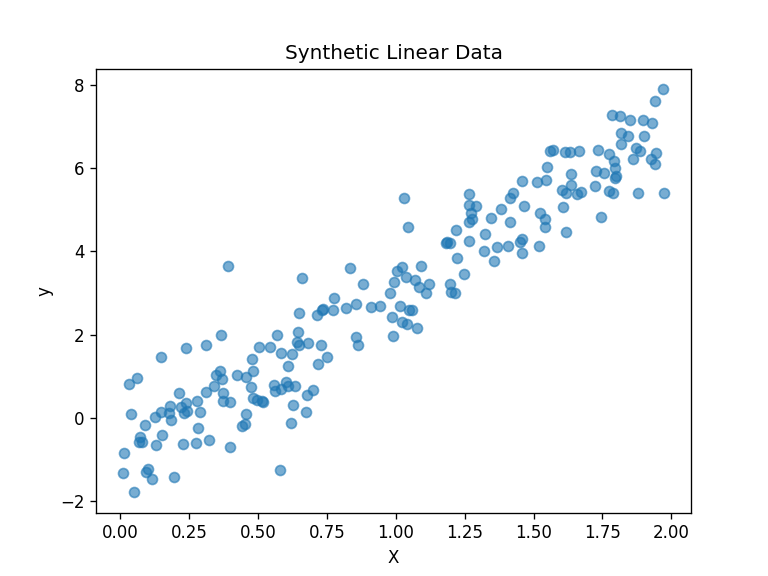

In [1]:
# 1.1 Generate synthetic linear data
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n_samples = 200
X_lin = 2 * np.random.rand(n_samples, 1)
true_slope = 4.0
true_intercept = -1.0
noise = np.random.randn(n_samples, 1) * 0.8
y_lin = true_slope * X_lin + true_intercept + noise

# Reshape for consistency
X_lin = X_lin.reshape(-1, 1)
y_lin = y_lin.reshape(-1, 1)

# Optional: visualize
plt.scatter(X_lin, y_lin, alpha=0.6)
plt.title('Synthetic Linear Data')
plt.xlabel('X')
plt.ylabel('y')
plt.show()
def train_test_split_numpy(X, y, test_size=0.2, seed=42):
    if len(X) != len(y) or len(X) < 2 or not 0 < test_size < 1:
        raise ValueError("Need matching arrays, >=2 observations and 0<test_size<1")
    indices = np.random.default_rng(seed).permutation(len(X))
    n_test = max(1, min(len(X)-1, int(np.ceil(test_size*len(X)))))
    test, train = indices[:n_test], indices[n_test:]
    return X[train], X[test], y[train], y[test]

def paired_targets(y_true, y_pred):
    true, pred = np.asarray(y_true).reshape(-1), np.asarray(y_pred).reshape(-1)
    if len(true) == 0 or true.shape != pred.shape:
        raise ValueError("Targets must have the same nonzero length")
    return true, pred


X_train_lin, X_test_lin, y_train_lin, y_test_lin = train_test_split_numpy(X_lin, y_lin)


### 1.2 Implement Linear Regression from Scratch

Complete the **TODO** sections below to implement a `LinearRegressionGD` class using gradient descent. Use **Mean Squared Error (MSE)** as the loss and update the weights and bias accordingly.

Recall:
- Loss: $$J(w, b) = \frac{1}{n}\sum_{i=1}^n (y_i - (w x_i + b))^2$$
- Gradient w.r.t. weight: $$\frac{\partial J}{\partial w} = -\frac{2}{n} \sum_{i=1}^n x_i (y_i - (w x_i + b))$$
- Gradient w.r.t. bias: $$\frac{\partial J}{\partial b} = -\frac{2}{n} \sum_{i=1}^n (y_i - (w x_i + b))$$


In [2]:
# 1.2 Linear Regression (Gradient Descent)
class LinearRegressionGD:
    def __init__(self, lr=0.05, n_iters=1000):
        self.lr = lr
        self.n_iters = n_iters
        self.weight = None  # shape: (n_features, 1)
        self.bias = None

    def fit(self, X, y):
        """
        X: numpy array of shape (n_samples, n_features)
        y: numpy array of shape (n_samples, 1)
        """
        y = np.asarray(y).reshape(-1, 1)
        if len(X) != len(y) or len(y) == 0:
            raise ValueError("Need matching nonempty X and y")
        n_samples, n_features = X.shape
        # Initialize parameters
        self.weight = np.zeros((n_features, 1))
        self.bias = 0.0

        # Gradient descent loop
        for i in range(self.n_iters):
            # Compute predictions
            y_pred = np.dot(X, self.weight) + self.bias

            # Compute gradients dw and db
            dw = (2/n_samples) * np.dot(X.T, (y_pred - y))
            db = (2/n_samples) * np.sum(y_pred - y)

            # Update parameters
            self.weight -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        """
        X: numpy array of shape (n_samples, n_features)
        returns: predictions of shape (n_samples, 1)
        """
        return np.dot(X, self.weight) + self.bias


### 1.3 Evaluate linear regression

Train on 80% of the data; report both training and held-out MSE and R². The factor of two in the gradient matches the stated full MSE loss. Constant-target R² returns 1 for perfect predictions and 0 otherwise.


In [3]:
def mean_squared_error(y_true, y_pred):
    true, pred = paired_targets(y_true, y_pred)
    return float(np.mean((true-pred)**2))

def r2_score(y_true, y_pred):
    true, pred = paired_targets(y_true, y_pred)
    residual = float(np.sum((true-pred)**2))
    total = float(np.sum((true-true.mean())**2))
    if total == 0:
        return 1.0 if residual == 0 else 0.0
    return 1 - residual/total

model_lin = LinearRegressionGD(lr=0.05, n_iters=2000)
model_lin.fit(X_train_lin, y_train_lin)
linear_results = {}
for name, X, y in [("train",X_train_lin,y_train_lin),("test",X_test_lin,y_test_lin)]:
    pred = model_lin.predict(X)
    linear_results[name] = {"mse":mean_squared_error(y,pred), "r2":r2_score(y,pred)}
print("Linear regression:", linear_results)
print("Fitted slope and intercept:",model_lin.weight.ravel(),model_lin.bias)


Linear regression: {'train': {'mse': 0.6150786304414582, 'r2': 0.8960120924830096}, 'test': {'mse': 0.5318687317916959, 'r2': 0.9163544246822076}}
Fitted slope and intercept: [3.94256187] -0.913922530947356


## 2. Logistic Regression

**Objective:** Implement binary logistic regression using gradient descent on a synthetic dataset. Evaluate using accuracy, precision, recall, and plot the decision boundary.

### 2.1 Generate Synthetic Binary Classification Data

We will generate two Gaussian blobs for classes 0 and 1.


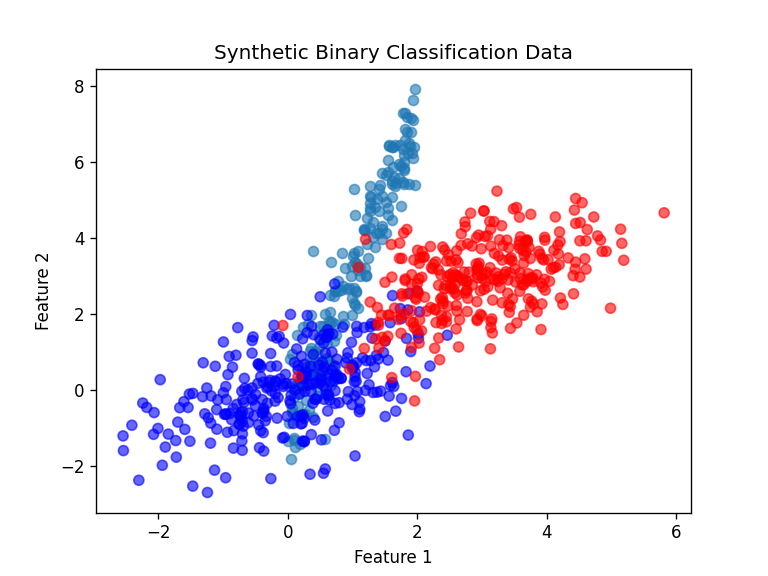

In [4]:
# 2.1 Generate synthetic data for logistic regression
np.random.seed(0)
num_obs = 300
mean0 = [0, 0]
cov0 = [[1, 0.5], [0.5, 1]]
mean1 = [3, 3]
cov1 = [[1, 0.5], [0.5, 1]]

x0 = np.random.multivariate_normal(mean0, cov0, num_obs)
x1 = np.random.multivariate_normal(mean1, cov1, num_obs)

X_log = np.vstack((x0, x1))  # shape: (2*num_obs, 2)
y_log = np.hstack((np.zeros(num_obs), np.ones(num_obs)))  # shape: (2*num_obs,)

# Optional: visualize the data
import matplotlib.pyplot as plt
plt.scatter(X_log[:, 0], X_log[:, 1], c=y_log, cmap='bwr', alpha=0.6)
plt.title('Synthetic Binary Classification Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split_numpy(X_log, y_log)


### 2.2 Implement Logistic Regression from Scratch

Complete the **TODO** sections below to implement a `LogisticRegressionGD` class. Use the **sigmoid** function and **Binary Cross-Entropy** loss:

- Sigmoid: $$\sigma(z) = \frac{1}{1 + e^{-z}}$$
- Loss: $$J(w, b) = -\frac{1}{n} \sum_{i=1}^n [y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i)]$$
- Gradients:
  - $$\frac{\partial J}{\partial w} = \frac{1}{n} X^T (\hat{y} - y)$$
  - $$\frac{\partial J}{\partial b} = \frac{1}{n} \sum_{i=1}^n (\hat{y}_i - y_i)$$


In [5]:
# 2.2 Logistic Regression (Gradient Descent)
class LogisticRegressionGD:
    def __init__(self, lr=0.1, n_iters=1000):
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None  # shape: (n_features,)
        self.bias = None      # scalar

    def sigmoid(self, z):
        # Implement sigmoid function
        z = np.asarray(z, dtype=float)
        result = np.empty_like(z)
        positive = z >= 0
        result[positive] = 1 / (1 + np.exp(-z[positive]))
        exp_z = np.exp(z[~positive])
        result[~positive] = exp_z / (1 + exp_z)
        return result

    def fit(self, X, y):
        """
        X: numpy array of shape (n_samples, n_features)
        y: numpy array of shape (n_samples,)
        """
        y = np.asarray(y).reshape(-1)
        if len(X) != len(y) or len(y) == 0 or not np.all(np.isin(y,[0,1])):
            raise ValueError("Need matching nonempty data and binary labels")
        n_samples, n_features = X.shape
        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for i in range(self.n_iters):
            # Compute linear model and predictions
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self.sigmoid(linear_model)

            # Compute gradients
            dw = (1/n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1/n_samples) * np.sum(y_predicted - y)

            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        # Compute probabilities using sigmoid
        linear_model = np.dot(X, self.weights) + self.bias
        return self.sigmoid(linear_model)

    def predict(self, X):
        """
        Return class labels 0 or 1
        """
        proba = self.predict_proba(X)
        return np.where(proba >= 0.5, 1, 0)


### 2.3 Evaluate logistic regression

Train on the training split and compare accuracy, precision and recall on train and test. The boundary plot shows held-out observations. Precision and recall use class 1 as positive, returning 0 for zero denominators.


Logistic regression: {'train': {'accuracy': 0.9645833333333333, 'precision': 0.9595141700404858, 'recall': 0.9713114754098361}, 'test': {'accuracy': 0.9166666666666666, 'precision': 0.896551724137931, 'recall': 0.9285714285714286}}


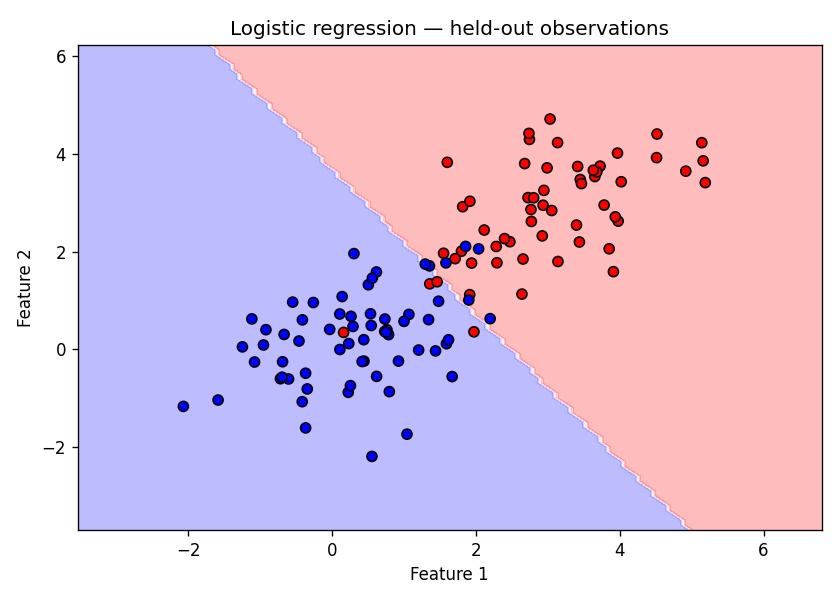

In [6]:
def accuracy_score(y_true, y_pred):
    true, pred = paired_targets(y_true,y_pred)
    return float(np.mean(true==pred))

def precision_score(y_true, y_pred):
    true, pred = paired_targets(y_true,y_pred)
    tp = np.sum((true==1)&(pred==1))
    denominator = np.sum(pred==1)
    return float(tp/denominator) if denominator else 0.0

def recall_score(y_true, y_pred):
    true, pred = paired_targets(y_true,y_pred)
    tp = np.sum((true==1)&(pred==1))
    denominator = np.sum(true==1)
    return float(tp/denominator) if denominator else 0.0

model_log = LogisticRegressionGD(lr=0.1,n_iters=2000)
model_log.fit(X_train_log,y_train_log)
logistic_results = {}
for name,X,y in [("train",X_train_log,y_train_log),("test",X_test_log,y_test_log)]:
    pred = model_log.predict(X)
    logistic_results[name] = {"accuracy":accuracy_score(y,pred),"precision":precision_score(y,pred),"recall":recall_score(y,pred)}
print("Logistic regression:",logistic_results)
x_min,x_max=X_log[:,0].min()-1,X_log[:,0].max()+1
y_min,y_max=X_log[:,1].min()-1,X_log[:,1].max()+1
xx,yy=np.meshgrid(np.linspace(x_min,x_max,100),np.linspace(y_min,y_max,100))
grid=np.c_[xx.ravel(),yy.ravel()]
plt.figure(figsize=(7,5))
plt.contourf(xx,yy,model_log.predict(grid).reshape(xx.shape),alpha=.3,cmap='bwr')
plt.scatter(X_test_log[:,0],X_test_log[:,1],c=y_test_log,cmap='bwr',edgecolors='k')
plt.title('Logistic regression — held-out observations')
plt.xlabel('Feature 1');plt.ylabel('Feature 2')
plt.tight_layout();plt.savefig('results/logistic_boundary.png',dpi=140);plt.show()


## 3. Decision Tree Classifier

**Objective:** Implement a binary decision tree classifier using **Gini impurity** for splits. Train and evaluate on a synthetic dataset.

### 3.1 Generate Synthetic Data for Decision Tree

We will generate a 2D dataset with non-linear separation to illustrate decision tree capabilities.


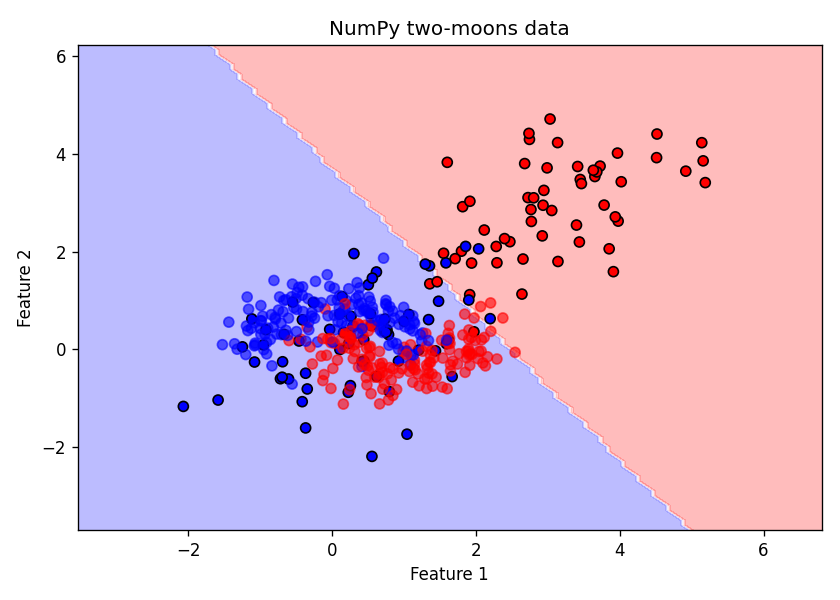

In [7]:
def make_moons_numpy(n_samples=300, noise=0.3, seed=42):
    rng = np.random.default_rng(seed)
    first = n_samples//2
    a = np.linspace(0,np.pi,first)
    b = np.linspace(0,np.pi,n_samples-first)
    X = np.vstack((np.c_[np.cos(a),np.sin(a)],np.c_[1-np.cos(b),.5-np.sin(b)]))
    y = np.r_[np.zeros(first,dtype=int),np.ones(n_samples-first,dtype=int)]
    X += rng.normal(0,noise,X.shape)
    order = rng.permutation(n_samples)
    return X[order],y[order]

X_dt,y_dt = make_moons_numpy()
plt.scatter(X_dt[:,0],X_dt[:,1],c=y_dt,cmap='bwr',alpha=.6)
plt.title('NumPy two-moons data')
plt.show()


### 3.2 Implement Decision Tree from Scratch

Complete the **TODO** sections to build a binary decision tree using **Gini impurity**.

Gini impurity for a node: $$G = 1 - \sum_{c} p_c^2$$
where $p_c$ is the proportion of class $c$ instances in the node.

**Steps:**
1. For each feature, consider all possible split thresholds (e.g., unique feature values).
2. Compute Gini impurity of left and right child nodes.
3. Select feature and threshold that minimize the weighted average Gini.
4. Recursively build subtrees until a stopping condition (e.g., max depth or pure node).


In [8]:
# 3.2 Decision Tree Classifier
class DecisionTree:
    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.tree = None

    class Node:
        def __init__(self, feature_index=None, threshold=None, left=None, right=None, *, value=None):
            self.feature_index = feature_index
            self.threshold = threshold
            self.left = left
            self.right = right
            self.value = value  # for leaf node

    def fit(self, X, y):
        y = np.asarray(y).reshape(-1)
        if len(X) != len(y) or len(y) == 0:
            raise ValueError("Need matching nonempty X and y")
        self.tree = self._build_tree(X, y)

    def _build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        # Stopping conditions
        if (depth >= self.max_depth) or (n_labels == 1) or (n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return self.Node(value=leaf_value)

        best_feature, best_thresh, best_gini = None, None, 1.0
        X_left, X_right, y_left, y_right = None, None, None, None

        # For each feature
        for feature_index in range(n_features):
            thresholds = np.unique(X[:, feature_index])
            for threshold in thresholds:
                left_idxs = np.where(X[:, feature_index] <= threshold)[0]
                right_idxs = np.where(X[:, feature_index] > threshold)[0]

                if len(left_idxs) == 0 or len(right_idxs) == 0:
                    continue

                gini_left = self._gini(y[left_idxs])
                gini_right = self._gini(y[right_idxs])
                weighted_gini = (len(left_idxs) / n_samples) * gini_left + (len(right_idxs) / n_samples) * gini_right

                if weighted_gini < best_gini:
                    best_gini = weighted_gini
                    best_feature = feature_index
                    best_thresh = threshold
                    X_left, X_right = X[left_idxs, :], X[right_idxs, :]
                    y_left, y_right = y[left_idxs], y[right_idxs]

        if best_feature is None:
            leaf_value = self._most_common_label(y)
            return self.Node(value=leaf_value)

        # Recursively build left and right subtrees
        left_subtree = self._build_tree(X_left, y_left, depth + 1)
        right_subtree = self._build_tree(X_right, y_right, depth + 1)
        return self.Node(feature_index=best_feature, threshold=best_thresh, left=left_subtree, right=right_subtree)

    def _gini(self, y):
        """
        Compute Gini impurity for labels y
        """
        m = len(y)
        if m == 0:
            return 0
        probs = [np.sum(y == c) / m for c in np.unique(y)]
        return 1 - sum(p**2 for p in probs)

    def _most_common_label(self, y):
        """
        Return the most common label in y
        """
        vals, counts = np.unique(y, return_counts=True)
        return vals[np.argmax(counts)]

    def predict(self, X):
        """
        Predict class labels for samples in X
        """
        return np.array([self._traverse_tree(x, self.tree) for x in X])

    def _traverse_tree(self, x, node):
        if node.value is not None:
            return node.value
        if x[node.feature_index] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)


### 3.3 Train and Evaluate Decision Tree

1. Split `(X_dt, y_dt)` into a training and test set (e.g., 80/20 split).
2. Instantiate `DecisionTree`, call `fit` on the training set.
3. Get predictions on both train and test sets.
4. Compute **Accuracy** and **Confusion Matrix** (reuse your functions or reimplement).


Decision tree: {'train': {'accuracy': 0.9125, 'confusion_matrix': [[109, 11], [10, 110]]}, 'test': {'accuracy': 0.9, 'confusion_matrix': [[25, 5], [1, 29]]}}


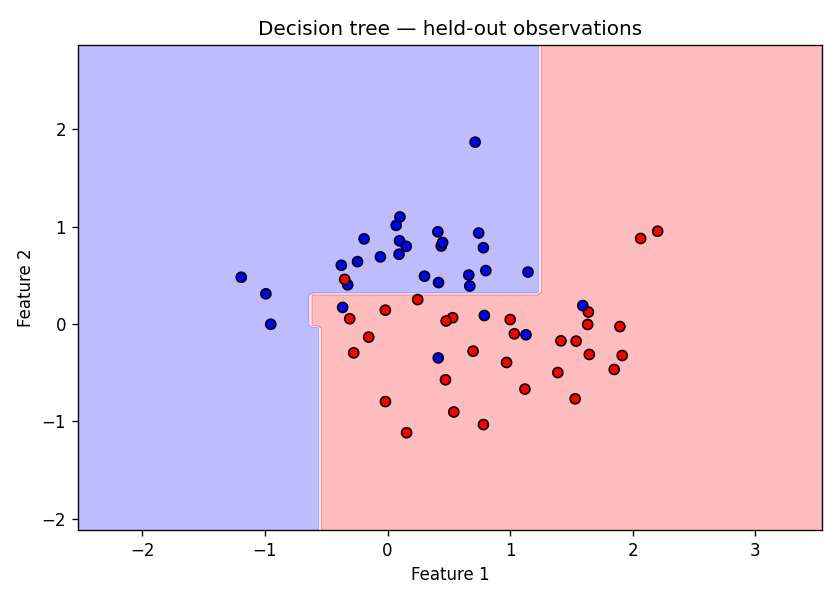

In [9]:
def confusion_matrix(y_true, y_pred, labels=None):
    true, pred = paired_targets(y_true,y_pred)
    labels = np.unique(np.r_[true,pred]) if labels is None else np.asarray(labels)
    if len(np.unique(labels)) != len(labels) or not np.all(np.isin(np.r_[true,pred],labels)):
        raise ValueError("Labels must uniquely cover all true and predicted classes")
    return np.array([[np.sum((true==a)&(pred==b)) for b in labels] for a in labels],dtype=int)

X_train_dt,X_test_dt,y_train_dt,y_test_dt = train_test_split_numpy(X_dt,y_dt)
dt_model = DecisionTree(max_depth=4)
dt_model.fit(X_train_dt,y_train_dt)
tree_results = {}
for name,X,y in [("train",X_train_dt,y_train_dt),("test",X_test_dt,y_test_dt)]:
    pred=dt_model.predict(X)
    tree_results[name] = {"accuracy":accuracy_score(y,pred),"confusion_matrix":confusion_matrix(y,pred,labels=[0,1]).tolist()}
print("Decision tree:",tree_results)
xx_dt,yy_dt=np.meshgrid(np.linspace(X_dt[:,0].min()-1,X_dt[:,0].max()+1,150),np.linspace(X_dt[:,1].min()-1,X_dt[:,1].max()+1,150))
plt.figure(figsize=(7,5))
plt.contourf(xx_dt,yy_dt,dt_model.predict(np.c_[xx_dt.ravel(),yy_dt.ravel()]).reshape(xx_dt.shape),alpha=.3,cmap='bwr')
plt.scatter(X_test_dt[:,0],X_test_dt[:,1],c=y_test_dt,cmap='bwr',edgecolors='k')
plt.title('Decision tree — held-out observations')
plt.xlabel('Feature 1');plt.ylabel('Feature 2')
plt.tight_layout();plt.savefig('results/tree_boundary.png',dpi=140);plt.show()


## Interpretation and provenance

The synthetic datasets illustrate each model's behavior, not performance on real-world applications. The Gaussian blobs are nearly linearly separable, while noisy moons have a nonlinear boundary. Compare train and held-out metrics rather than reporting training accuracy alone. The NumPy moons generator is new in this edition and its seeded samples differ from the original scikit-learn data. No Gaussian Naive Bayes code was supplied. Correctness revisions and new experiments are documented in README.
